## **import libraries**

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt

## **load data**

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'


In [3]:
df = pd.read_csv(data, sep=',')

# **EDA**

## **view first 5 rows of data**

In [4]:
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [5]:
df.columns = df.columns.str.lower()

In [6]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

## 

## **data cleaning**

In [7]:
status_variables = {
    1: 'ok', 
    2: 'default', 
    0: 'unk'
}

df.status = df.status.map(status_variables)

home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk',
}
df.home = df.home.map(home_values)

marital_status = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}
df.marital = df.marital.map(marital_status)


record_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}
df.records = df.records.map(record_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}
df.job = df.job.map(job_values)


In [8]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [9]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [10]:
df.isna().sum()

status       0
seniority    0
home         0
time         0
age          0
marital      0
records      0
job          0
expenses     0
income       0
assets       0
debt         0
amount       0
price        0
dtype: int64

In [11]:
for c in ['income', 'assets', 'debt']:

    df[c] = df[c].replace(to_replace = 99999999.0, value = np.nan)

In [12]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [13]:
df = df[df.status != 'unk'].reset_index(drop = True)

In [14]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state = 11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state = 11)


In [15]:
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

In [16]:
y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

In [17]:
del df_train['status']
del df_val['status']
del df_test['status']

In [18]:
df_train

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,10,owner,36,36,married,no,freelance,75,0.0,10000.0,0.0,1000,1400
1,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330
2,1,parents,48,40,married,no,fixed,75,121.0,0.0,0.0,1320,1600
3,1,parents,48,23,single,no,partime,35,72.0,0.0,0.0,1078,1079
4,5,owner,36,46,married,no,freelance,60,100.0,4000.0,0.0,1100,1897
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2667,18,private,36,45,married,no,fixed,45,220.0,20000.0,0.0,800,1600
2668,7,private,60,29,married,no,fixed,60,51.0,3500.0,500.0,1000,1290
2669,1,parents,24,19,single,no,fixed,35,28.0,0.0,0.0,400,600
2670,15,owner,48,43,married,no,freelance,60,100.0,18000.0,0.0,2500,2976


## **Model training**

In [19]:
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'partime':
            return 'default'
        else:
            return 'ok'

    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'

In [20]:
xi = df_train.loc[0].to_dict()
xi

assess_risk(xi)

'ok'

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [22]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

In [23]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_train

array([[3.60e+01, 1.00e+03, 1.00e+04, ..., 0.00e+00, 1.00e+01, 3.60e+01],
       [3.20e+01, 1.10e+03, 0.00e+00, ..., 1.00e+00, 6.00e+00, 4.80e+01],
       [4.00e+01, 1.32e+03, 0.00e+00, ..., 0.00e+00, 1.00e+00, 4.80e+01],
       ...,
       [1.90e+01, 4.00e+02, 0.00e+00, ..., 0.00e+00, 1.00e+00, 2.40e+01],
       [4.30e+01, 2.50e+03, 1.80e+04, ..., 0.00e+00, 1.50e+01, 4.80e+01],
       [2.70e+01, 4.50e+02, 5.00e+03, ..., 1.00e+00, 1.20e+01, 4.80e+01]],
      shape=(2672, 29))

In [24]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [25]:
val_dicts = df_val.fillna(0).to_dict(orient = 'records')
X_val = dv.transform(val_dicts)

In [30]:
y_pred = dt.predict_proba(X_val)[:, 1]
y_pred

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 1., 1., 0., 0., 0., 0.,
       1., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0.,
       0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 1., 0., 1., 0., 0.,
       0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 0., 1., 1., 0., 0., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 1., 1., 0., 1., 0., 0., 0.,
       1., 0., 0., 1., 1., 1., 0., 1., 1., 1., 1., 0., 1., 1., 1., 0., 0.,
       0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 1., 1., 0., 1., 0., 1.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 1., 0.,
       0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
       1., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
       0., 0., 0., 1., 0.

In [27]:
roc_auc_score(y_val, y_pred)

0.6627533845147854

In [28]:
y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

1.0

### *model seems to overfit*

## **handling overfitting by limitting max depth**

In [32]:
dt = DecisionTreeClassifier(max_depth=3)
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [33]:
y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print("train auc:", auc)

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print("val auc:", auc)

train auc: 0.7761016984958594
val auc: 0.7389079944782155


In [34]:
from sklearn.tree import export_text

In [35]:
print(export_text(dt, feature_names = dv.get_feature_names_out()))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- class: 0
|   |   |--- amount >  862.50
|   |   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- income <= 103.50
|   |   |   |--- class: 1
|   |   |--- income >  103.50
|   |   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- class: 0
|   |   |--- income >  74.50
|   |   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- assets <= 8750.00
|   |   |   |--- class: 1
|   |   |--- assets >  8750.00
|   |   |   |--- class: 0



## **parameter tuning**

In [36]:
scores = []

for d in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=d)
    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_train)[:, 1]
    train_auc = round(roc_auc_score(y_train, y_pred), 3)
    # print("train auc:", f"{train_auc:.3f}")

    y_pred = dt.predict_proba(X_val)[:, 1]
    val_auc = round(roc_auc_score(y_val, y_pred), 3)
    # print("val auc:", f"{val_auc:.3f}")

    scores.append((d, train_auc, val_auc, abs((train_auc - val_auc))))
# print(scores)
pd.DataFrame(scores, columns = ['max_depth', 'train_auc', 'val_auc', 'diff']).set_index('max_depth').sort_values('diff', ascending = True)


,train_auc,val_auc,diff
max_depth,,,
1.0,0.628,0.606,0.022
2.0,0.705,0.669,0.036
3.0,0.776,0.739,0.037
4.0,0.816,0.761,0.055
5.0,0.843,0.766,0.077
6.0,0.874,0.750,0.124
10.0,0.964,0.691,0.273
15.0,0.999,0.665,0.334
NaN,1.000,0.661,0.339


## *best depth around 4*

In [37]:
new_scores = []

for d in [4, 5, 6, 7, 10, 15, 20, None]:
    for s in [1, 2, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth = d, min_samples_leaf = s)
        dt.fit(X_train, y_train)
    
        y_pred = dt.predict_proba(X_train)[:, 1]
        train_auc = round(roc_auc_score(y_train, y_pred), 3)
        # print("train auc:", f"{train_auc:.3f}")
    
        y_pred = dt.predict_proba(X_val)[:, 1]
        val_auc = round(roc_auc_score(y_val, y_pred), 3)
        # print("val auc:", f"{val_auc:.3f}")
        
        new_scores.append((d, s, train_auc, val_auc, abs((train_auc - val_auc))))
        # print(scores)
auc_df = pd.DataFrame(
    new_scores, 
    columns = ['max_depth', 'samples_leaf', 'train_auc', 'val_auc', 'diff']
    ).sort_values('val_auc', ascending = False)  
auc_df.head()

,max_depth,samples_leaf,train_auc,val_auc,diff
40,10.0,15,0.901,0.790,0.111
67,NaN,15,0.904,0.789,0.115
58,20.0,15,0.904,0.788,0.116
49,15.0,15,0.904,0.785,0.119
41,10.0,20,0.891,0.785,0.106


In [38]:
pivot_df = auc_df.pivot(index = 'samples_leaf', columns = ['max_depth'], values = ['val_auc'])
pivot_df

val_auc                                                 
max_depth        NaN   4.0    5.0    6.0    7.0    10.0   15.0   20.0
samples_leaf                                                         
1              0.663  0.761  0.767  0.761  0.733  0.681  0.655  0.656
2              0.694  0.761  0.766  0.767  0.749  0.727  0.679  0.690
5              0.716  0.761  0.768  0.759  0.756  0.726  0.712  0.709
10             0.761  0.761  0.762  0.778  0.764  0.766  0.761  0.759
15             0.789  0.764  0.772  0.785  0.780  0.790  0.785  0.788
20             0.782  0.761  0.774  0.774  0.779  0.785  0.784  0.782
100            0.780  0.756  0.763  0.776  0.780  0.779  0.779  0.780
200            0.768  0.747  0.759  0.768  0.768  0.768  0.768  0.768
500            0.680  0.680  0.680  0.680  0.680  0.680  0.680  0.680

In [39]:
import seaborn as sns

<Axes: xlabel='None-max_depth', ylabel='samples_leaf'>

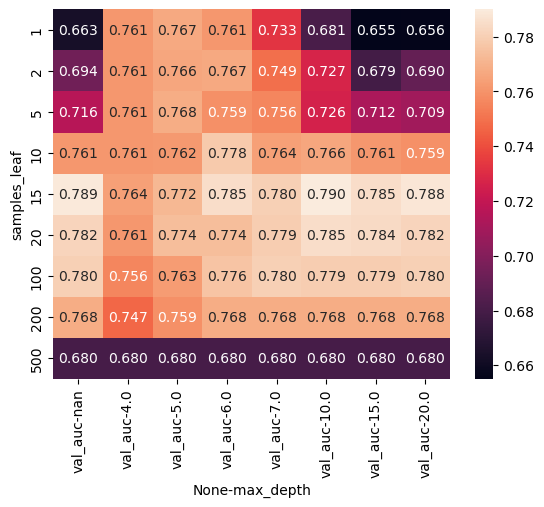

In [40]:
sns.heatmap(pivot_df, annot = True, fmt = '.3f')

## **final decision tree model**

In [41]:
dt = DecisionTreeClassifier(max_depth = 6, min_samples_leaf = 15)
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,15
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


## **Random Forest**

In [42]:
from sklearn.ensemble import RandomForestClassifier

In [43]:
rf = RandomForestClassifier(
    # max_depth = 10, 
    # min_samples_leaf = 15, 
    n_estimators = 10 ,
    random_state = 1
)
rf.fit(X_train, y_train)

,n_estimators,10
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [44]:
y_pred = rf.predict_proba(X_val)[:, 1]  

roc_auc_score(y_val, y_pred)

0.7744726453706618

In [45]:
rf.predict_proba(X_val[[0]])

array([[0.9, 0.1]])

In [46]:
scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(
        n_estimators = n,
        random_state = 1
    )
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = round(roc_auc_score(y_val, y_pred), 3)
    scores.append((n, auc))

In [47]:
df_scores = pd.DataFrame(
    scores, 
    columns = ['n_estimators', 'val_auc']
    ).set_index('n_estimators').sort_values('val_auc', ascending = False)

df_scores

,val_auc
n_estimators,
200,0.819
100,0.818
190,0.818
170,0.818
160,0.818
140,0.818
130,0.818
120,0.818
110,0.818


<Axes: xlabel='n_estimators'>

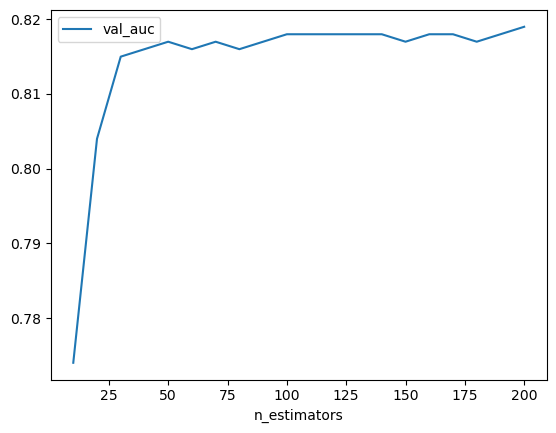

In [48]:
sns.lineplot(df_scores)

In [49]:
scores = []

for d in [5, 10, 15, None]:
    # for leaf in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(
                n_estimators=n,
                max_depth=d,
                # min_samples_leaf=leaf,
                random_state=1,
                # n_jobs=-1,
        )
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = round(roc_auc_score(y_val, y_pred), 3)
        scores.append((d, n, auc))

In [50]:
df_scores = pd.DataFrame(
    scores, 
    columns = ['max_depth', 'n_estimators', 'val_auc']
    ).set_index('n_estimators').sort_values('val_auc', ascending = False)

df_scores.loc[50]

,max_depth,val_auc
n_estimators,,
50,NaN,0.817
50,10.0,0.817
50,15.0,0.813
50,5.0,0.800


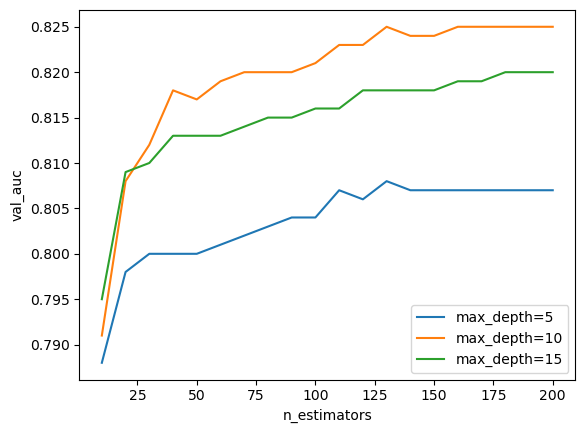

In [51]:
for d in [5, 10, 15]:
    df_subset = df_scores[df_scores['max_depth'] == d]
    sns.lineplot(data=df_subset, x='n_estimators', y='val_auc', label=f'max_depth={d}')

In [52]:
scores = []

for s in [1, 3, 5, 10, 50]:
    # for leaf in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(
                n_estimators = n,
                max_depth = 10,
                min_samples_leaf = s,
                random_state=1,
                # n_jobs=-1,
        )
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = round(roc_auc_score(y_val, y_pred), 3)
        scores.append((s, n, auc))

In [53]:
df_scores = pd.DataFrame(
    scores, 
    columns = ['min_samples_leaf', 'n_estimators', 'val_auc']
    ).set_index('n_estimators').sort_values('val_auc', ascending = False)

df_scores.loc[50]

,min_samples_leaf,val_auc
n_estimators,,
50,3,0.823
50,10,0.822
50,5,0.821
50,1,0.817
50,50,0.805


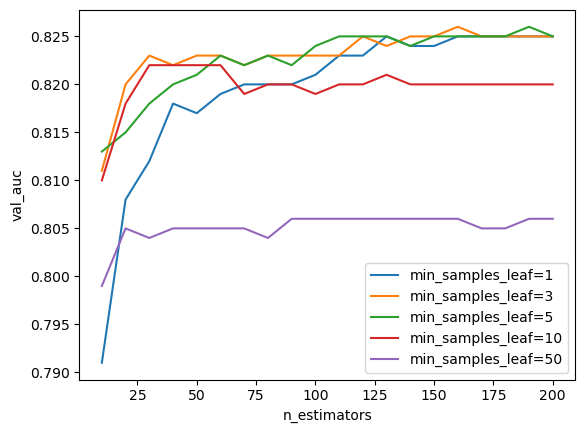

In [54]:
for s in [1, 3, 5, 10, 50]:
    df_subset = df_scores[df_scores['min_samples_leaf'] == s]
    sns.lineplot(data=df_subset, x='n_estimators', y='val_auc', label=f'min_samples_leaf={s}')

In [55]:
min_samples_leaf = 3

## **final randomforest model**

In [56]:
rf = RandomForestClassifier(
        n_estimators = 100,
        max_depth = 10,
        min_samples_leaf = min_samples_leaf,
        random_state=1,
        n_jobs=-1,
)

rf.fit(X_train, y_train)

# y_pred = rf.predict_proba(X_val)[:, 1]
# auc = round(roc_auc_score(y_val, y_pred), 3)
# scores.append((s, n, auc))

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,3
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## **Gradient Boosting**

In [57]:
import xgboost as xgb

In [58]:
dv.get_feature_names_out()

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [59]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)


In [60]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round = 10
)

In [61]:
y_pred = model.predict(dval)

In [62]:
roc_auc_score(y_val, y_pred)

0.8156256811411687

In [63]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [64]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(
    xgb_params,
    dtrain,
    evals = watchlist,
    verbose_eval = 5,
    num_boost_round = 200
)

In [65]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns = columns)
    return df_results

In [66]:
df_score = parse_xgb_output(output)
df_score.head()

,num_iter,train_auc,val_auc
0,0,0.86632,0.77998
1,5,0.93359,0.81150
2,10,0.95391,0.82002
3,15,0.97087,0.82220
4,20,0.97677,0.82239


<Axes: ylabel='val_auc'>

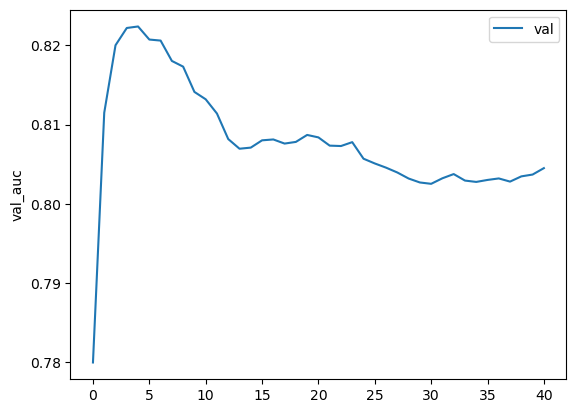

In [67]:
# sns.lineplot(df_score['train_auc'], label = 'train')
sns.lineplot(df_score['val_auc'], label = 'val')

In [68]:
np.linspace(0,1,11)

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

In [69]:
scores = {}
watchlist = [(dtrain, 'train'), (dval, 'val')]

for eta in [0.01, 0.05, 0.1, 0.3, 1.0]:
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    evals_result = {}
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=200,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=5
    )

    key = f'eta={eta}'
    scores[key] = pd.DataFrame({
        'num_iter': range(len(evals_result['val']['auc'])),
        'train_auc': evals_result['train']['auc'],
        'val_auc': evals_result['val']['auc'],
    })

[0]	train-auc:0.86632	val-auc:0.77998


[5]	train-auc:0.87007	val-auc:0.77821
[10]	train-auc:0.87208	val-auc:0.77838
[15]	train-auc:0.87381	val-auc:0.78277
[20]	train-auc:0.87584	val-auc:0.78719
[25]	train-auc:0.88595	val-auc:0.79571
[30]	train-auc:0.89329	val-auc:0.80000
[35]	train-auc:0.89642	val-auc:0.79971
[40]	train-auc:0.89881	val-auc:0.79866
[45]	train-auc:0.90066	val-auc:0.79690
[50]	train-auc:0.90259	val-auc:0.79705
[55]	train-auc:0.90401	val-auc:0.79737
[60]	train-auc:0.90552	val-auc:0.79690
[65]	train-auc:0.90670	val-auc:0.79633
[70]	train-auc:0.90816	val-auc:0.79749
[75]	train-auc:0.90974	val-auc:0.79862
[80]	train-auc:0.91118	val-auc:0.79924
[85]	train-auc:0.91239	val-auc:0.80075
[90]	train-auc:0.91393	val-auc:0.80254
[95]	train-auc:0.91541	val-auc:0.80339
[100]	train-auc:0.91684	val-auc:0.80390
[105]	train-auc:0.91797	val-auc:0.80428
[110]	train-auc:0.91933	val-auc:0.80442
[115]	train-auc:0.92046	val-auc:0.80430
[120]	train-auc:0.92178	val-auc:0.80471
[125]	train-auc:0.92317	val-auc:0.80516
[130]	train-auc:0.92

In [70]:
scores

{'eta=0.01':      num_iter  train_auc   val_auc
 0           0   0.866320  0.779979
 1           1   0.866410  0.779804
 2           2   0.866544  0.779767
 3           3   0.868510  0.778541
 4           4   0.869220  0.778348
 ..        ...        ...       ...
 195       195   0.937462  0.814778
 196       196   0.937631  0.814766
 197       197   0.937860  0.814881
 198       198   0.938014  0.814845
 199       199   0.938091  0.815117
 
 [200 rows x 3 columns],
 'eta=0.05':      num_iter  train_auc   val_auc
 0           0   0.866320  0.779979
 1           1   0.869836  0.774064
 2           2   0.871839  0.778002
 3           3   0.874687  0.783209
 4           4   0.877436  0.787230
 ..        ...        ...       ...
 195       195   0.989001  0.827768
 196       196   0.989139  0.827841
 197       197   0.989218  0.827580
 198       198   0.989252  0.827496
 199       199   0.989633  0.827696
 
 [200 rows x 3 columns],
 'eta=0.1':      num_iter  train_auc   val_auc
 0         

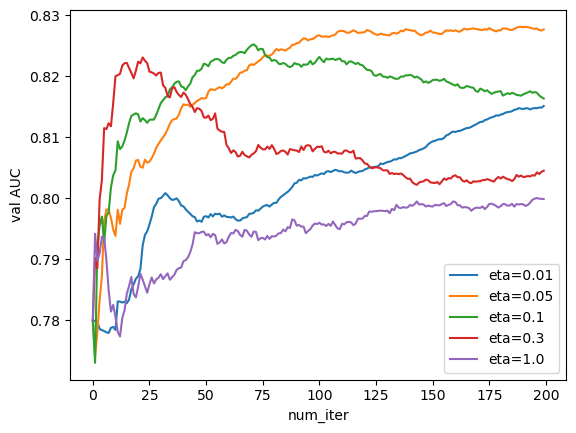

In [71]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.xlabel('num_iter')
plt.ylabel('val AUC')
plt.legend()
plt.show()

In [72]:
scores.keys()

dict_keys(['eta=0.01', 'eta=0.05', 'eta=0.1', 'eta=0.3', 'eta=1.0'])

In [73]:
eta = 0.05

In [74]:
scores_2 = {}
watchlist = [(dtrain, 'train'), (dval, 'val')]

for max_depth in [3, 4, 6, 10]:
    xgb_params = {
        'eta': eta,
        'max_depth': max_depth,
        'min_child_weight': 1,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    evals_result = {}
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=200,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=5
    )

    key = f'max_depth={max_depth}'
    scores_2[key] = pd.DataFrame({
        'num_iter': range(len(evals_result['val']['auc'])),
        'train_auc': evals_result['train']['auc'],
        'val_auc': evals_result['val']['auc'],
    })

[0]	train-auc:0.77610	val-auc:0.73891


[5]	train-auc:0.82506	val-auc:0.77525
[10]	train-auc:0.83338	val-auc:0.77606
[15]	train-auc:0.84484	val-auc:0.78475
[20]	train-auc:0.85108	val-auc:0.79175
[25]	train-auc:0.85606	val-auc:0.79844
[30]	train-auc:0.86098	val-auc:0.80355
[35]	train-auc:0.86567	val-auc:0.80786
[40]	train-auc:0.86895	val-auc:0.81069
[45]	train-auc:0.87165	val-auc:0.81278
[50]	train-auc:0.87439	val-auc:0.81395
[55]	train-auc:0.87660	val-auc:0.81462
[60]	train-auc:0.88027	val-auc:0.81622
[65]	train-auc:0.88284	val-auc:0.81748
[70]	train-auc:0.88497	val-auc:0.81871
[75]	train-auc:0.88691	val-auc:0.82028
[80]	train-auc:0.88908	val-auc:0.82146
[85]	train-auc:0.89119	val-auc:0.82216
[90]	train-auc:0.89311	val-auc:0.82338
[95]	train-auc:0.89512	val-auc:0.82517
[100]	train-auc:0.89683	val-auc:0.82625
[105]	train-auc:0.89873	val-auc:0.82712
[110]	train-auc:0.90007	val-auc:0.82754
[115]	train-auc:0.90146	val-auc:0.82834
[120]	train-auc:0.90263	val-auc:0.82845
[125]	train-auc:0.90376	val-auc:0.82884
[130]	train-auc:0.90

In [75]:
scores_2.keys()

dict_keys(['max_depth=3', 'max_depth=4', 'max_depth=6', 'max_depth=10'])

In [76]:
scores_2

{'max_depth=3':      num_iter  train_auc   val_auc
 0           0   0.776102  0.738908
 1           1   0.777175  0.739919
 2           2   0.810665  0.776310
 3           3   0.810048  0.775929
 4           4   0.825618  0.777676
 ..        ...        ...       ...
 195       195   0.918235  0.832188
 196       196   0.918408  0.832291
 197       197   0.918587  0.832406
 198       198   0.918838  0.832327
 199       199   0.918961  0.832249
 
 [200 rows x 3 columns],
 'max_depth=4':      num_iter  train_auc   val_auc
 0           0   0.816653  0.760008
 1           1   0.817162  0.758243
 2           2   0.819125  0.763423
 3           3   0.821200  0.764440
 4           4   0.832220  0.781075
 ..        ...        ...       ...
 195       195   0.947266  0.829300
 196       196   0.947409  0.829415
 197       197   0.947515  0.829500
 198       198   0.947856  0.829409
 199       199   0.947937  0.829433
 
 [200 rows x 3 columns],
 'max_depth=6':      num_iter  train_auc   val_auc
 

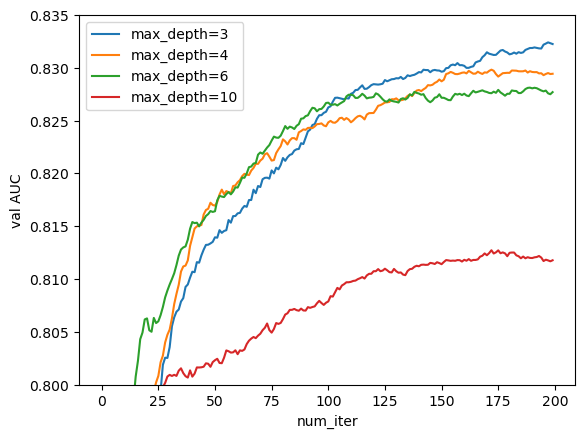

In [77]:
for key, df_score in scores_2.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.xlabel('num_iter')
plt.ylabel('val AUC')
plt.ylim(0.8, 0.835)
plt.legend()
plt.show()

In [78]:
max_depth = 3

In [79]:
scores_3 = {}
watchlist = [(dtrain, 'train'), (dval, 'val')]

for min_child_weight in [2, 3, 4, 6, 10, 30]:
    xgb_params = {
        'eta': eta,
        'max_depth': max_depth,
        'min_child_weight': min_child_weight,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    evals_result = {}
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=200,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=5
    )

    key = f'max_depth={min_child_weight}'
    scores_3[key] = pd.DataFrame({
        'num_iter': range(len(evals_result['val']['auc'])),
        'train_auc': evals_result['train']['auc'],
        'val_auc': evals_result['val']['auc'],
    })

[0]	train-auc:0.77610	val-auc:0.73891


[5]	train-auc:0.82506	val-auc:0.77525
[10]	train-auc:0.83338	val-auc:0.77606
[15]	train-auc:0.84484	val-auc:0.78475
[20]	train-auc:0.85108	val-auc:0.79175
[25]	train-auc:0.85606	val-auc:0.79844
[30]	train-auc:0.86096	val-auc:0.80349
[35]	train-auc:0.86561	val-auc:0.80776
[40]	train-auc:0.86864	val-auc:0.81019
[45]	train-auc:0.87180	val-auc:0.81210
[50]	train-auc:0.87442	val-auc:0.81382
[55]	train-auc:0.87785	val-auc:0.81538
[60]	train-auc:0.88088	val-auc:0.81663
[65]	train-auc:0.88312	val-auc:0.81794
[70]	train-auc:0.88514	val-auc:0.81923
[75]	train-auc:0.88742	val-auc:0.82104
[80]	train-auc:0.88934	val-auc:0.82186
[85]	train-auc:0.89092	val-auc:0.82305
[90]	train-auc:0.89287	val-auc:0.82418
[95]	train-auc:0.89413	val-auc:0.82480
[100]	train-auc:0.89601	val-auc:0.82589
[105]	train-auc:0.89749	val-auc:0.82664
[110]	train-auc:0.89904	val-auc:0.82681
[115]	train-auc:0.90034	val-auc:0.82715
[120]	train-auc:0.90166	val-auc:0.82737
[125]	train-auc:0.90294	val-auc:0.82744
[130]	train-auc:0.90

In [80]:
scores_3.keys()

dict_keys(['max_depth=2', 'max_depth=3', 'max_depth=4', 'max_depth=6', 'max_depth=10', 'max_depth=30'])

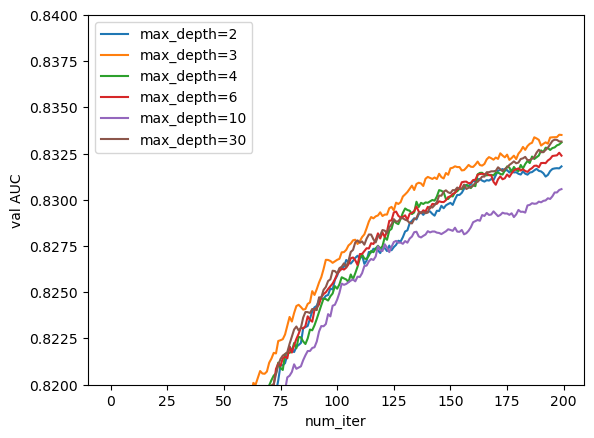

In [81]:
for key, df_score in scores_3.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.xlabel('num_iter')
plt.ylabel('val AUC')
plt.ylim(0.82, 0.84)
plt.legend()
plt.show()

## **best randon forest model**

In [82]:
xgb_params = {
    'eta': 0.05,
    'max_depth': 3,
    'min_child_weight': 30,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}


model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=175,
)



## **selecting the final model**

In [83]:
dt = DecisionTreeClassifier(max_depth = 6, min_samples_leaf = 15)
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,15
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [84]:
y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.785470804775859

In [85]:
rf = RandomForestClassifier(
        n_estimators = 100,
        max_depth = 10,
        min_samples_leaf = min_samples_leaf,
        random_state=1,
        n_jobs=-1,
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,3
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [87]:
y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8233361991717324

In [ ]:
xgb_params = {
    'eta': 0.05,
    'max_depth': 3,
    'min_child_weight': 30,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=175,
)


In [88]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8316673124894045

In [90]:
df_full_train = df_full_train.reset_index(drop = True)

In [91]:
y_full_train = (df_full_train.status == 'default').astype(int).values

In [92]:
del df_full_train['status']

In [ ]:
dicts = df_full_train.to_dict(orient = 'records')

dv = DictVectorizer(sparse = True)
X_full_train = dv.fit
